In [28]:
import os 
from matplotlib import pyplot as plt
import numpy as np
from sklearn.mixture import GaussianMixture
import sourmash
import polars as pl
import glob
import seaborn as sns
import collections
from scipy.stats import norm
from pprint import pprint

In [2]:
import sys
sys.path.insert(0, '../../2026-cassie-fit-gcp')
import fitgcp_lib

pysam available: False


In [35]:
def plot_fit(fit, *, max_x=None, plot_observed=False):
    ds = fit["dataset"]
    mm = fit["model"]

    if max_x is None:
        max_x = int(np.max(ds.cov))

    xs = np.arange(max_x + 1)

    observed = np.zeros(max_x + 1, dtype=float)
    valid = ds.cov <= max_x
    observed[ds.cov[valid].astype(int)] = ds.count[valid] / np.sum(ds.count)

    #plt.figure(figsize=(9, 5))
    if plot_observed:
        plt.plot(xs, observed, linewidth=2, label="Observed GCP")

    total = np.zeros_like(xs, dtype=float)

    for idx, d in enumerate(mm[1:]):
        print(d)
        pprint(d.report_stats())
        y = d.alpha * d.pmf(xs)
        total += y
        plt.plot(xs, y, label=f"{idx}: {d._name}")
        plt.show()

    plt.plot(xs, total, linestyle="--", linewidth=2, label="Total Mixture")
    #plt.xlabel("Coverage")
    #plt.ylabel("Fraction of Genome Positions")
    #plt.title("Genome Coverage Profile and Fitted Mixture")
    #plt.legend()
    #plt.tight_layout()
    #plt.show()



In [36]:
def load_fit_plot_isect(species, metag, *, ymax=50, bins=50, num_components=None, verbose=True, model=None, threshold=1e-4):
    ss = list(sourmash.load_file_as_signatures(f'../outputs.isect/3216_isect.d/{species} singlehash.x.{metag}.sig.zip'))[0]

    values = np.array(list(ss.minhash.hashes.values())).reshape(-1, 1)

     # track hashval abundance distribution
    counts_d = collections.defaultdict(int)
    # track abundance distribution, too
    counter = collections.Counter()

    for hashval, abund in ss.minhash.hashes.items():
        counts_d[hashval] += abund
        counter[abund] += 1

    all_counts = list(counts_d.values())
    counts_dist = list(counter.items())
    sum_hist = sum(counter.values())
    max_range = max(counter.values())
    min_range = 0

    # find count that covers 95% of distribution.
    sofar = 0
    for k, v in sorted(counts_dist):
        sofar += v
        if sofar >= 0.99*sum_hist:
            max_range = 2*k
            break

    fig, ax1 = plt.subplots(nrows=1, ncols=1, figsize=(10, 4))
    sns.histplot(all_counts, ax=ax1,
                 binrange=(min_range, max_range),
                 bins=bins, kde=False, stat='density')

    ### GCP
    if model is None:
        model = "pnt"
    cov_ds = fitgcp_lib.DataSet.from_coverage_vector(values)
    fitfit = fitgcp_lib.fit_gcp(cov_ds, model=model, max_iterations=100, threshold=threshold)
    
    print("Iterations:", len(fitfit["history"]))
    print("Final Diagnostic:", fitfit["history"][-1])

    plot_fit(fitfit)
    
    fig.suptitle(f'{species}.x.{metag}')
    plt.legend(loc='upper right')

    plt.show()

In [37]:
xx = np.unique(np.array([1,1,2,3,3,5,5,5]), return_counts=True)
xx

(array([1, 2, 3, 5]), array([2, 1, 2, 3]))

In [38]:
np.cumsum(xx[0])

array([ 1,  3,  6, 11])

XXX 1 cutoff_target=1432.6 cutoff=33
XXX2 fallback_mean=13.950980392156863
XXX3 initial_means=[np.float64(6.9754901960784315), np.float64(20.926470588235293)]
XXX3 {'iteration': 1, 'max_parameter_change': np.float64(2.5e+19), 'max_cdf_difference': np.float64(0.15130032961820275)}
XXX3 {'iteration': 2, 'max_parameter_change': np.float64(0.6793728353297498), 'max_cdf_difference': np.float64(0.13089209981106117)}
XXX3 {'iteration': 3, 'max_parameter_change': np.float64(0.4947480093289583), 'max_cdf_difference': np.float64(0.0938999836553901)}
XXX3 {'iteration': 4, 'max_parameter_change': np.float64(0.36035676183540766), 'max_cdf_difference': np.float64(0.05883743381336623)}
XXX3 {'iteration': 5, 'max_parameter_change': np.float64(0.22130272239289334), 'max_cdf_difference': np.float64(0.04117965438270521)}
XXX3 {'iteration': 6, 'max_parameter_change': np.float64(0.08335342456673049), 'max_cdf_difference': np.float64(0.034692654481400936)}
XXX3 {'iteration': 7, 'max_parameter_change': np.fl

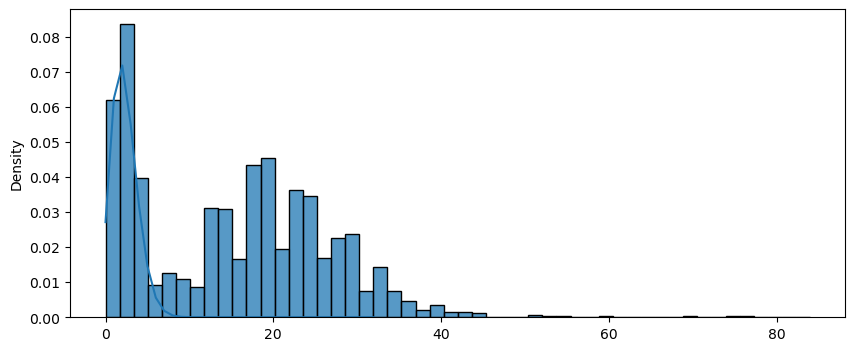

NBinom
{'alpha': np.float64(0.47594369525168145),
 'distribution': 'NBinom',
 'mean': np.float64(21.856114759972073),
 'parameter_1': np.float64(72.20677760897784),
 'parameter_2': np.float64(0.7676436030241958)}


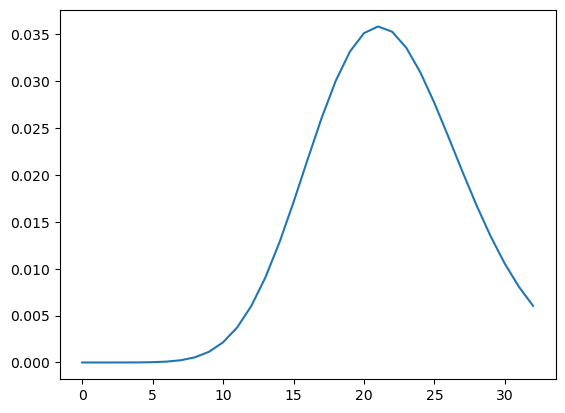

Tail of NBinom
{'alpha': np.float64(0.2529856836287026),
 'distribution': 'Tail of NBinom',
 'parameter_1': np.float64(72.20677760897784),
 'parameter_2': np.float64(0.7676436030241958)}


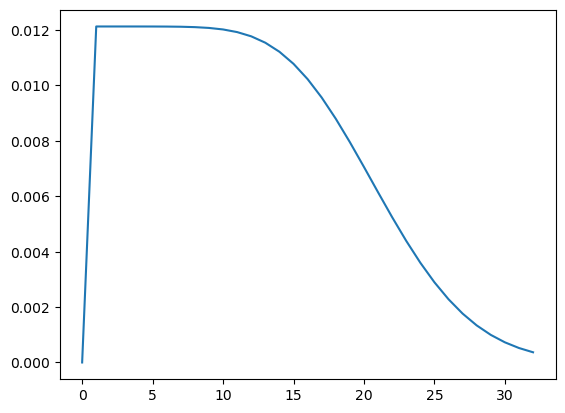

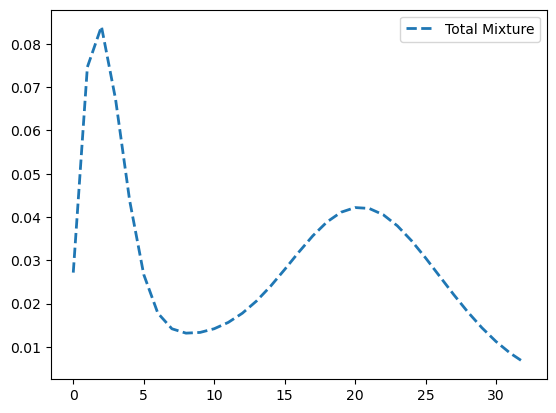

In [39]:
load_fit_plot_isect('GCA_945501735 s__Prevotella sp002251295', 'SRR14369134', model='zpnt')

XXX 1 cutoff_target=606.1 cutoff=2434
XXX2 fallback_mean=378.7293729372937
XXX3 initial_means=[np.float64(189.36468646864685), np.float64(378.7293729372937), np.float64(568.0940594059406)]
XXX3 {'iteration': 1, 'max_parameter_change': np.float64(2.0000000000000004e+19), 'max_cdf_difference': np.float64(0.29022538837856665)}
XXX3 {'iteration': 2, 'max_parameter_change': np.float64(2.9516083928172776), 'max_cdf_difference': np.float64(0.3027488516910101)}
XXX3 {'iteration': 3, 'max_parameter_change': np.float64(1.8099653616875282), 'max_cdf_difference': np.float64(0.27798019111506406)}
XXX3 {'iteration': 4, 'max_parameter_change': np.float64(1.48123030428435), 'max_cdf_difference': np.float64(0.2551607415980389)}
XXX3 {'iteration': 5, 'max_parameter_change': np.float64(1.2981058833749826), 'max_cdf_difference': np.float64(0.2363674578955987)}
XXX3 {'iteration': 6, 'max_parameter_change': np.float64(1.1723586040405336), 'max_cdf_difference': np.float64(0.22177905254627392)}
XXX3 {'iterati

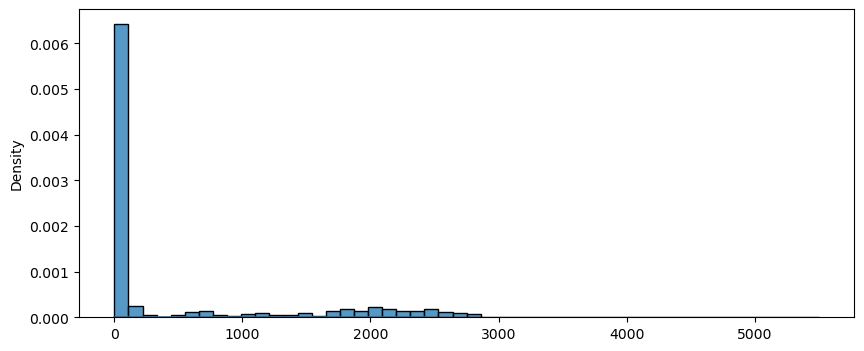

NBinom
{'alpha': np.float64(0.4566657508057741),
 'distribution': 'NBinom',
 'mean': np.float64(212.23272643867978),
 'parameter_1': np.float64(0.14083849581521204),
 'parameter_2': np.float64(0.0006631639670344687)}


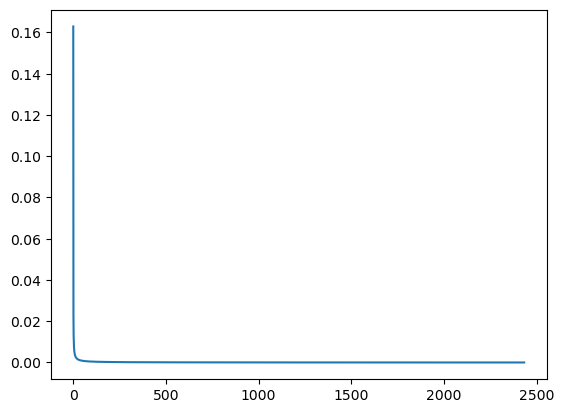

NBinom
{'alpha': np.float64(0.5025074065006961),
 'distribution': 'NBinom',
 'mean': np.float64(457.82823588913493),
 'parameter_1': np.float64(0.34976505311941886),
 'parameter_2': np.float64(0.0007633824679493961)}


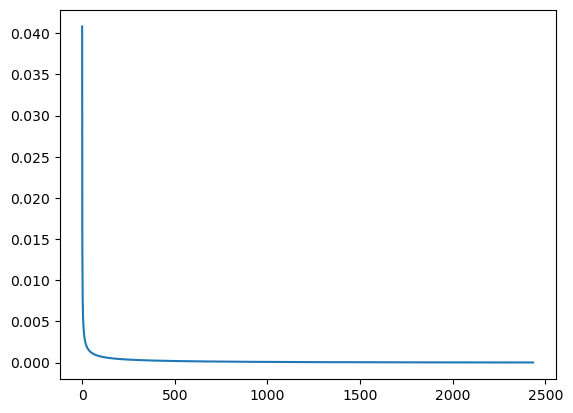

Tail of NBinom
{'alpha': np.float64(0.04081910503081087),
 'distribution': 'Tail of NBinom',
 'parameter_1': np.float64(0.34976505311941886),
 'parameter_2': np.float64(0.0007633824679493961)}


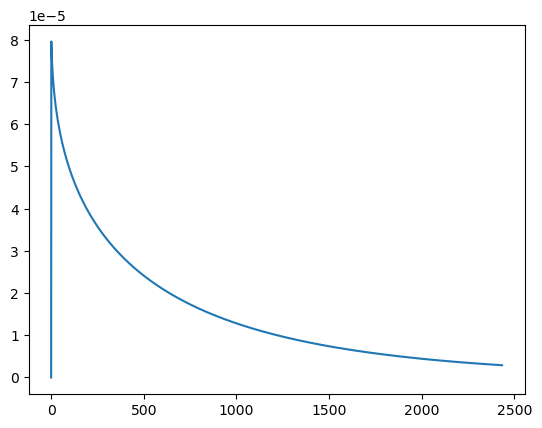

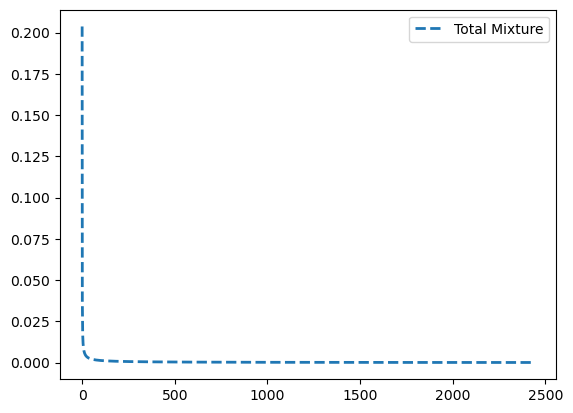

In [41]:
load_fit_plot_isect('GCF_028308525 s__Lactobacillus amylovorus', 'SRR11185260', threshold=1, model='zpnnt')

## Try out some good ones 

Iterations: 100
Final Diagnostic: {'iteration': 100, 'max_parameter_change': np.float64(0.24450204828873529), 'max_cdf_difference': np.float64(0.09290251734804089)}


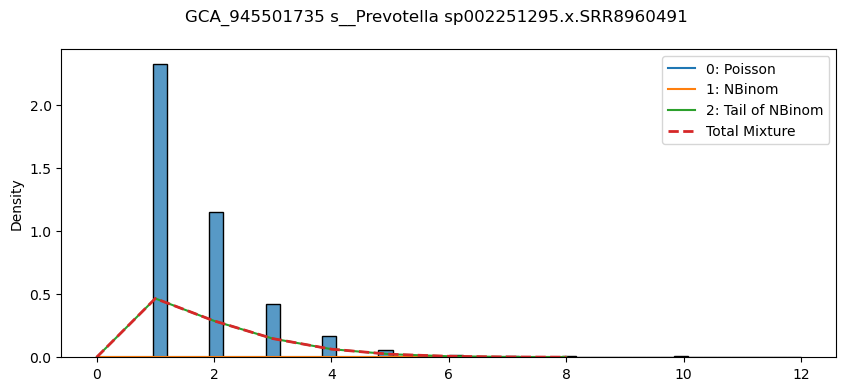

Iterations: 100
Final Diagnostic: {'iteration': 100, 'max_parameter_change': np.float64(0.1428983576471246), 'max_cdf_difference': np.float64(0.04044439031900854)}


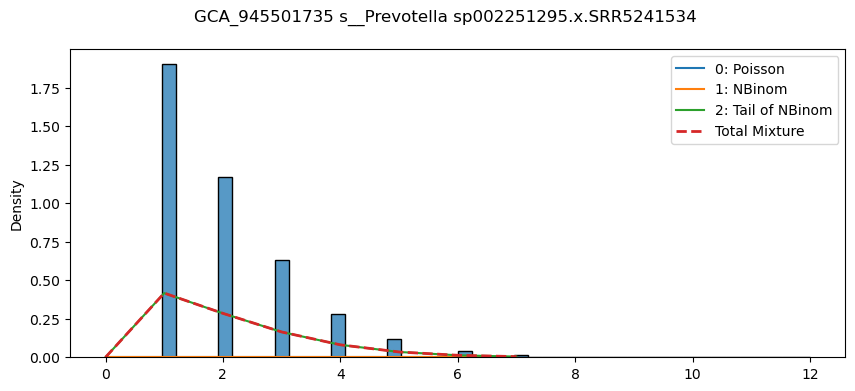

Iterations: 100
Final Diagnostic: {'iteration': 100, 'max_parameter_change': np.float64(0.000551701891114436), 'max_cdf_difference': np.float64(0.016346400187808197)}


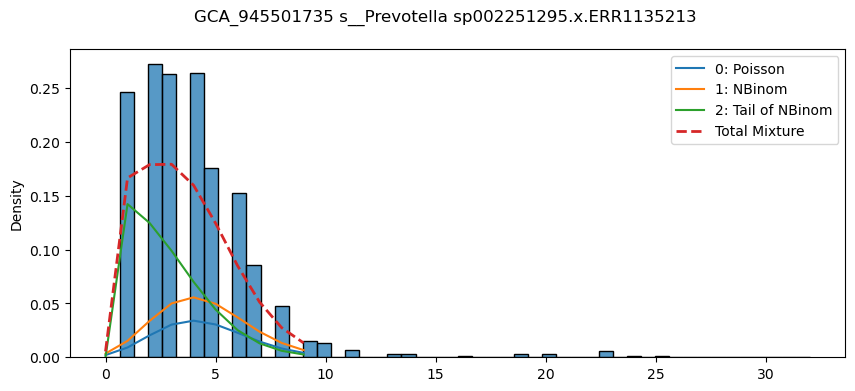

Iterations: 43
Final Diagnostic: {'iteration': 43, 'max_parameter_change': np.float64(9.657922562997561e-05), 'max_cdf_difference': np.float64(0.04579823618344901)}


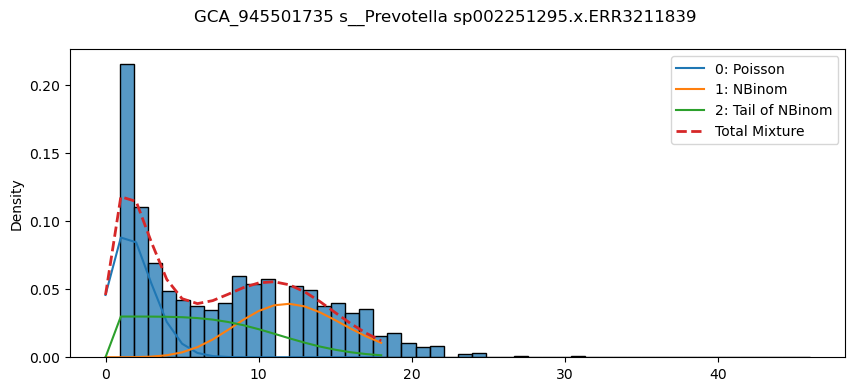

Iterations: 60
Final Diagnostic: {'iteration': 60, 'max_parameter_change': np.float64(9.23424803187908e-05), 'max_cdf_difference': np.float64(0.05447931181356486)}


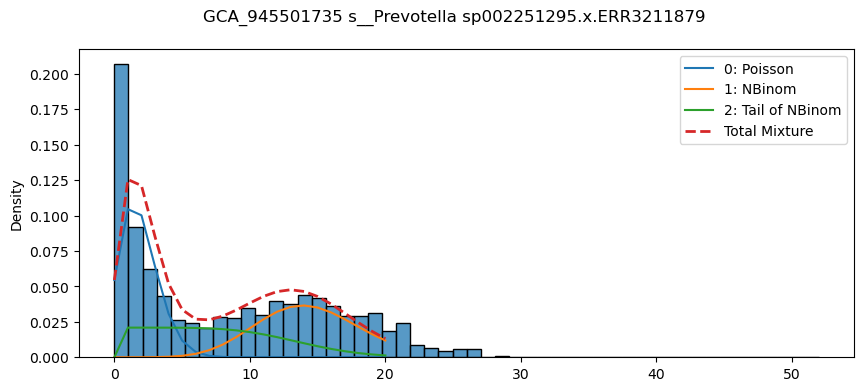

Iterations: 45
Final Diagnostic: {'iteration': 45, 'max_parameter_change': np.float64(9.42797139169809e-05), 'max_cdf_difference': np.float64(0.052619419542426125)}


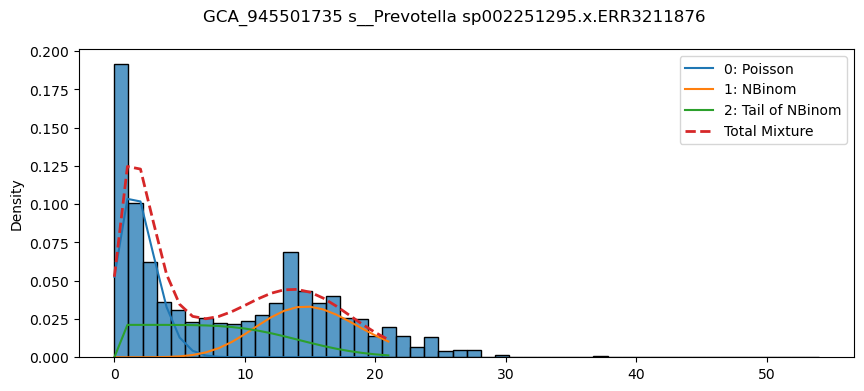

Iterations: 94
Final Diagnostic: {'iteration': 94, 'max_parameter_change': np.float64(9.914020948708678e-05), 'max_cdf_difference': np.float64(0.029185304012271762)}


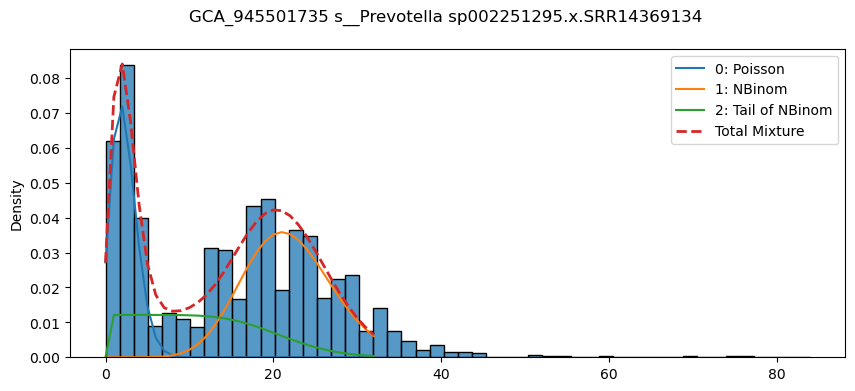

Iterations: 22
Final Diagnostic: {'iteration': 22, 'max_parameter_change': np.float64(8.209558612580851e-05), 'max_cdf_difference': np.float64(0.047306204166361554)}


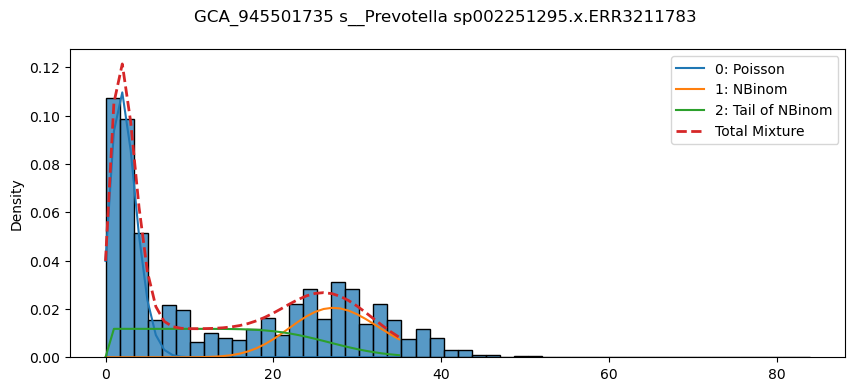

Iterations: 46
Final Diagnostic: {'iteration': 46, 'max_parameter_change': np.float64(9.72107789571346e-05), 'max_cdf_difference': np.float64(0.030502557615088965)}


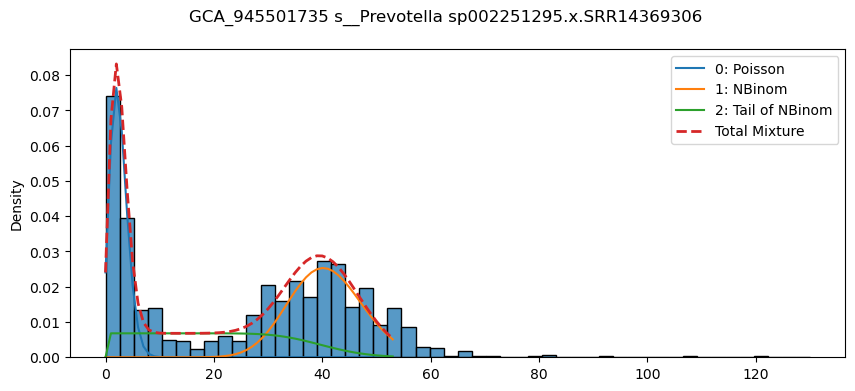

Iterations: 28
Final Diagnostic: {'iteration': 28, 'max_parameter_change': np.float64(8.634880926262228e-05), 'max_cdf_difference': np.float64(0.05055875659421388)}


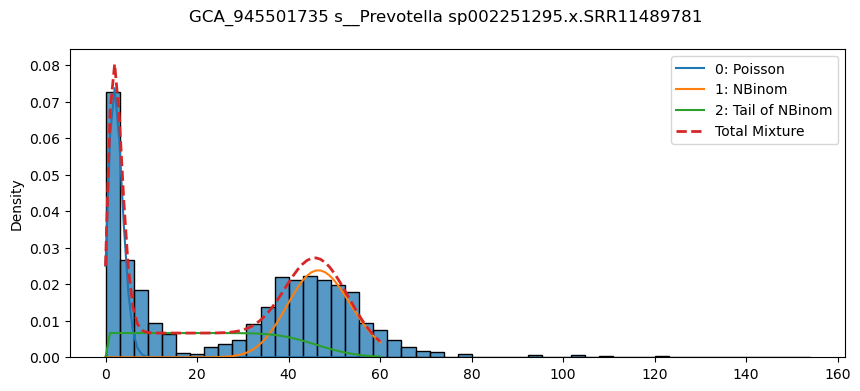

In [5]:
SS='GCA_945501735 s__Prevotella sp002251295'

METAGS=[
 'SRR8960491',
 'SRR5241534',
 'ERR1135213',
 'ERR3211839',
 'ERR3211879',
 'ERR3211876',
 'SRR14369134',
 'ERR3211783',
 'SRR14369306',
 'SRR11489781']

#plot_covhist_panel(SS, METAGS, ymax=100)

for i in METAGS:
    load_fit_plot_isect(SS, i)

Iterations: 100
Final Diagnostic: {'iteration': 100, 'max_parameter_change': np.float64(0.24450204828873529), 'max_cdf_difference': np.float64(0.09290251734804089)}


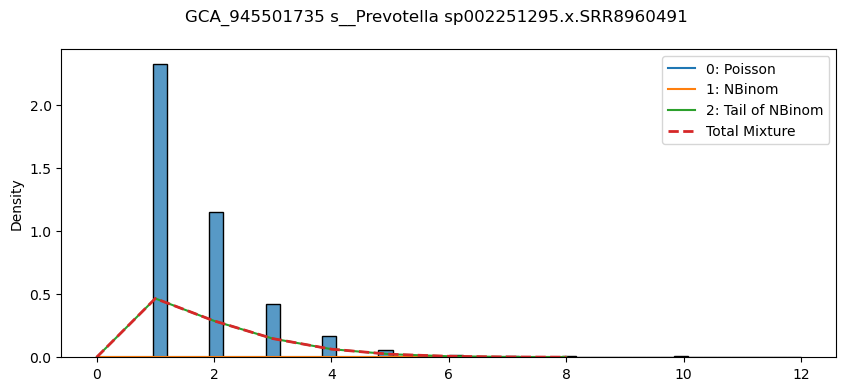

In [6]:
SS='GCA_945501735 s__Prevotella sp002251295'
load_fit_plot_isect(SS, 'SRR8960491')

## Misc prevotella IGNORE

## Load lacto kmer coverage estimates

In [7]:
lacto_kmer_df = pl.read_csv('../outputs.isect/s__Lactobacillus amylovorus.isect.abund.csv')

## Plot some high abundance ones

In [8]:
lacto_kmer_df = lacto_kmer_df.sort('abund', descending=True).drop_nans()
lacto_kmer_df

metag,species,abund
str,str,f64
"""SRR11185260""","""s__Lactobacillus amylovorus""",2282.732405
"""SRR11185246""","""s__Lactobacillus amylovorus""",2224.495096
"""SRR16235702""","""s__Lactobacillus amylovorus""",2045.930849
"""SRR16235689""","""s__Lactobacillus amylovorus""",1924.562551
"""SRR16235687""","""s__Lactobacillus amylovorus""",1839.80097
…,…,…
"""ERR3212024""","""s__Lactobacillus amylovorus""",1.0
"""ERR3211822""","""s__Lactobacillus amylovorus""",1.0
"""ERR3211990""","""s__Lactobacillus amylovorus""",1.0


In [10]:
for metag in lacto_kmer_df.head(1)['metag']:
    print(metag)
    break
    load_fit_plot_isect('GCF_028308525 s__Lactobacillus amylovorus', metag)

SRR11185260


In [ ]:
lacto_kmer_df

In [ ]:
depth_df = pl.read_csv('../mapping-depth.csv')

In [ ]:
lacto_depth_df = depth_df.filter(pl.col('gene') == 'AtH2023_SRR8960431_MAG03_43_3')

In [ ]:
lacto_depth_df

In [ ]:
lacto_all_df = lacto_depth_df.join(lacto_kmer_df, on='metag')
lacto_all_df

In [ ]:
MAX=1000
plt.plot(lacto_all_df['depth_all'], lacto_all_df['abund'], '*')
plt.plot([0, MAX], [0, MAX], '--')
plt.xlim(0, MAX)
plt.ylim(0, MAX)
plt.xlabel('mapping depth')
plt.ylabel('kmer depth')
plt.title('s__Lactobacillus amylovorus')

## Try out prevotella

In [ ]:
depth_df

In [ ]:
prevotella_kmer_df = pl.read_csv('../outputs.isect/s__Prevotella sp002251295.isect.abund.csv')

In [ ]:
prevotella_depth_df = depth_df.filter(pl.col('gene') == 'AtH2023_ERR3211937_MAG3_16_9')

In [ ]:
prevotella_all_df = prevotella_depth_df.join(prevotella_kmer_df, on='metag')

In [ ]:
MAX=400
plt.plot(prevotella_all_df['depth_all'], prevotella_all_df['abund'], '*')
plt.plot([0, MAX], [0, MAX], '--')
plt.xlim(0, MAX)
plt.ylim(0, MAX)
plt.xlabel('mapping depth')
plt.ylabel('kmer depth')
plt.title('s__Prevotella sp002251295')

## Plot all of the ones for which we have anchor genes?

In [ ]:
new_genes_df = pl.read_csv('../new_genes_df.csv')

In [ ]:
combo_genes_df = depth_df.join(new_genes_df.filter(pl.col('anchor') == 1), left_on='gene', right_on='gene_name', how='inner', coalesce=True)

In [50]:
combo_kmer_df = pl.read_csv('../outputs.isect/*.csv')

In [56]:
all_df = combo_genes_df.join(combo_kmer_df, on=['metag', 'species'], how='inner')

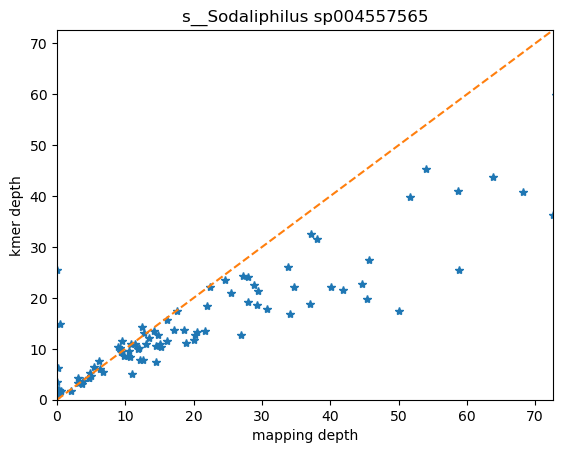

SKIPPING: s__Cryptobacteroides sp900546925
SKIPPING: s__Mogibacterium_A kristiansenii
SKIPPING: s__Cryptobacteroides sp034089285
SKIPPING: s__Colivicinus sp002299675
SKIPPING: s__Cryptobacteroides sp000434935
SKIPPING: s__Ornithospirochaeta sp022785155
SKIPPING: s__Floccifex porci


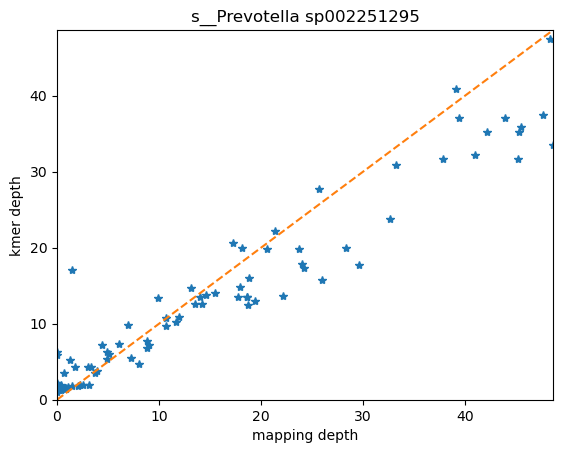

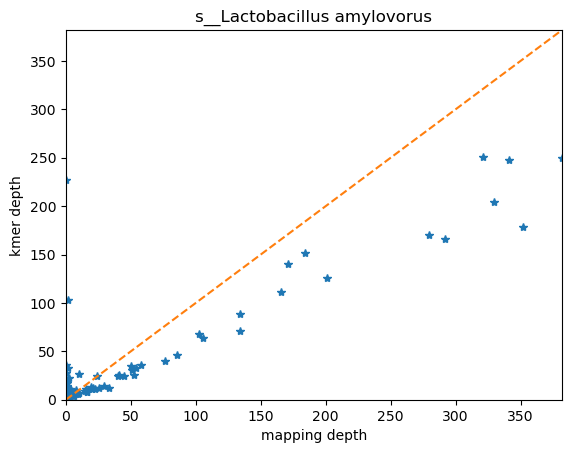

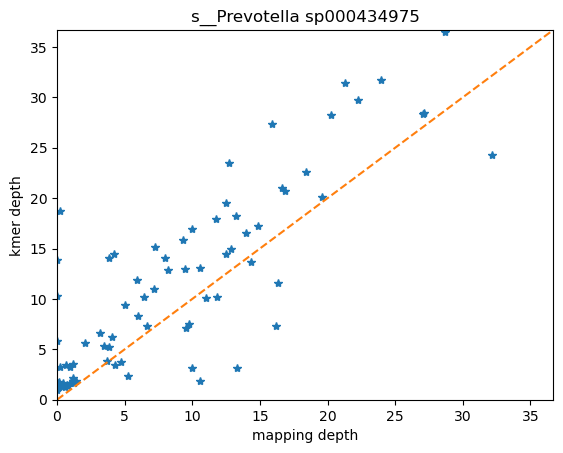

SKIPPING: s__Fimisoma sp002320005
SKIPPING: s__UBA2868 sp004552595


In [60]:
for species in all_df['species'].unique():
    xx_df = all_df.filter(pl.col('species') == species)

    depths = list(sorted(xx_df['depth_all']))
    MAX = depths[int(len(depths) * 0.9)]

    if MAX < 20:
        print('SKIPPING:', species)
        continue
    
    plt.plot(xx_df['depth_all'], xx_df['abund'], '*')
    plt.plot([0, MAX], [0, MAX], '--')
    plt.xlim(0, MAX)
    plt.ylim(0, MAX)
    plt.xlabel('mapping depth')
    plt.ylabel('kmer depth')
    plt.title(species)
    plt.show()